# Paper figures (v2)

Same layout as `2026-09-10_paper_figures.ipynb`, on the **v2 rerun**:
- **Training set:** `_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`, noise in θ, $n_\mathrm{train}=10\,000$ cosmologies, $b_x=32$.
- **Test sets:** independent IC phases for coverage (`_coveragev2_p5_n1000`) and the SHAMe-cosmology CV set (`_cvshamev2_p0_n1000`).
- **Statistics:** P_gm uses the "1" operator.
- **Hyperparameters:** from the `-rand16` sweeps.

**Fiducial (provisional):** $k_\mathrm{max}^{P_\mathrm{gg}}=0.37$, $k_\mathrm{max}^{B}=k_\mathrm{max}^{P_\mathrm{gm}}=0.24$ (`generate_config_inference.FIDUCIAL_MASKS`). The ensemble is an equal-weight **$K=3$** mixture. The scheme is set in the cell below: `top3_settings` (best_runs.txt lines 0–2, seed 0 each) or `seeds` (top setting, seeds 0–2). Figure caches are keyed on the scheme, so switching doesn't reuse stale arrays. The fiducial k_max and the ensemble are still being decided (`2026-11-19_v2_checks.ipynb` §2–3).

Plotting logic is in `code/plotter_figs.py`, and tags / masks / ensemble members are in `code/ensemble_kmax_utils.py`. The full combination is `pk_pgm_bispec` (masks `_kp_kpgm_kb`). Results use **un-reparameterized** parameters ($\Omega_\mathrm{c}$, $\sigma_8$, $b_1$) unless noted. Status of the inputs: `notes/v2_rerun_tracker.md`.

In [1]:
import os
import sys
from pathlib import Path

# v2 trees (code_auxiliary/env_v2.sh); must be set before importing paths / data_loader
os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import ensemble_kmax_utils as eku
import plotter_figs as pf

%load_ext autoreload
%autoreload 2

print("data:", pf.paths.DIR_DATA, "| results:", pf.paths.DIR_RESULTS)
print("train:", pf.TAG_PARAMS_TRAIN, pf.TAG_BIASPARAMS_TRAIN, pf.TAG_NOISE_TRAIN)
print("fiducial:", eku.FIDUCIAL_CONFIGS)

pf.configure_figures(
    save=True,
    fig_dir=REPO_ROOT / "figures" / "2026-11-20_paper_figures",
    fig_dir_latest=REPO_ROOT / "figures" / "paper_figures_v2_latest",
    ext="pdf",
)

2026-11-19 22:55:58.010211: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-19 22:55:58.061428: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-19 22:55:58.185138: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-19 22:55:58.185198: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-19 22:55:58.204856: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

2026-11-19 22:56:00.237681: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


data: /scratch/kstoreyf/muchisimocks/data_v2 | results: /scratch/kstoreyf/muchisimocks/results_v2
train: _p5_n10000 _biasnoisenestv2_p9_n320000 _noisefly
fiducial: [(['pk'], '_kp0.37'), (['pk', 'pgm'], '_kp0.37_kpgm0.24'), (['pk', 'bispec'], '_kp0.37_kb0.24'), (['pk', 'pgm', 'bispec'], '_kp0.37_kpgm0.24_kb0.24')]
SAVE_FIGURES: True
FIG_DIR: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures
FIG_DIR_LATEST: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest
OVERWRITE_FIGURES: True
FIG_EXT: pdf


{'SAVE_FIGURES': True,
 'FIG_DIR': PosixPath('/home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures'),
 'FIG_DIR_LATEST': PosixPath('/home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest'),
 'OVERWRITE_FIGURES': True,
 'FIG_EXT': 'pdf'}

In [2]:
# Fiducial ensemble (provisional: top-3 hyperparameter settings, as in v1). Options: eku.ENSEMBLE_SCHEMES
eku.set_ensemble_scheme("top3_settings")
for stats, mask in eku.FIDUCIAL_CONFIGS:
    print(f"{'_'.join(stats):15s}", [eku.model_dir(stats, mask, n).name.split("_best")[-1] for n in range(eku.N_ENSEMBLE_K)])

pk              ['-rand16', '-rand16_nbest1', '-rand16_nbest2']
pk_pgm          ['-rand16', '-rand16_nbest1', '-rand16_nbest2']
pk_bispec       ['-rand16', '-rand16_nbest1', '-rand16_nbest2']
pk_pgm_bispec   ['-rand16', '-rand16_nbest1', '-rand16_nbest2']


## 1. mMocks overview

Pipeline schematic - see paper


## 2. Statistics: training-set ranges

Median with 16–84% and 1–99% bands over the fiducial noisy training set.

- **SHAMe lines are unchanged from v1:** SHAMe P, P_gm and B were computed from the SHAMe catalogs and N-body matter field (`data/data_shame/data_nbar*/`, March 2026), and their binning matches v2 training (32 P/P_gm bins, 203 triangles). The v2 P_gm fix changed the *muchisimocks* side to agree with SHAMe's matter field, so the P_gm training band is the part that moved.
- **All three statistics are complete** for the v2 training set (P, P_gm, B: 320,000 rows each; bispec job 7975566 finished 2026-11-17), so the bispectrum band now uses every cosmology.


Loaded cache: /scratch/kstoreyf/muchisimocks/results_v2/paper_figures_cache/fig2_stat_ranges__p5_n10000_biasnoisenestv2_p9_n320000_noisefly_bx32_n100.pkl


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/fig2_statistics_ranges.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/fig2_statistics_ranges.pdf


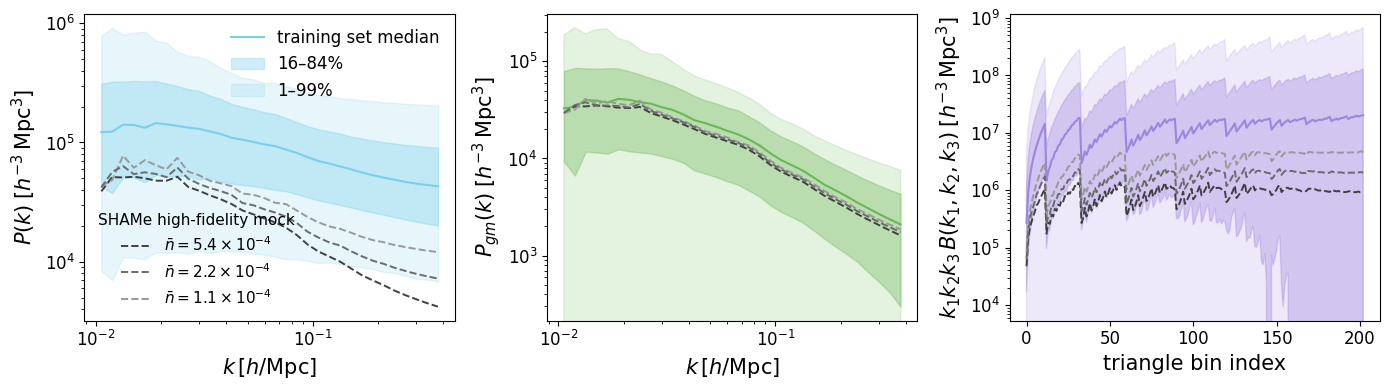

In [3]:
pf.plot_fig2_statistics_ranges()


## 3. Cosmic variance test (fixed cosmology, mean)

Contour plot on the mean of 1000 fixed-cosmo mocks. All four fiducial statistic combinations ($K{=}3$ ensemble).


In [4]:
pf.plot_fig3_cosmic_variance_contours()


keep (top-model samples on disk): [True, True, True, False]
ensemble keep (cvmean): [False, False, False, False]
  ensemble missing [$P_\mathrm{gg}$]: member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_muchisimocks_pk_kp0.37_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_muchisimocks_pk_kp0.37_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy
  ensemble missing [$P_\mathrm{gg}$ + $P_\mathrm{gm}$]: member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/sampl

## 4. Coverage test — prediction bias

Median and 16–84% of $\theta^{\mathrm{pred}} - \theta^{\mathrm{true}}$ vs true parameter value.


In [5]:
pf.plot_fig4_coverage_binned_diff()


coverage ensemble keep (K=3): [False, False, False, False]
Fig 4: no statistic combo has all 3 coverage members yet; skipping


add avg of the sigmas on top - if well calibrated, should match


## 5. Coverage test — PP plots

Nominal credibility vs empirical coverage of the central equal-tailed credible interval.

Same top-model coverage samples as Fig. 4 (new $k_{p,\mathrm{max}}=0.37$ masks).


In [6]:
pf.plot_fig5_coverage_pp_center()


coverage ensemble keep (K=3): [False, False, False, False]
Fig 5: no statistic combo has all 3 coverage members yet; skipping


## 6. SHAMe test

OOD galaxy catalog ($\bar n = 0.00022\,h^3/\mathrm{Mpc}^3$). Contours for all fiducial statistics ($K{=}3$ ensemble).


keep (top-model samples on disk): [True, True, True, False]
ensemble keep (shame): [True, True, True, False]
  ensemble missing [$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$]: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_nbar0.00022_pred.npy


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/fig6_shame_contours.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/fig6_shame_contours.pdf


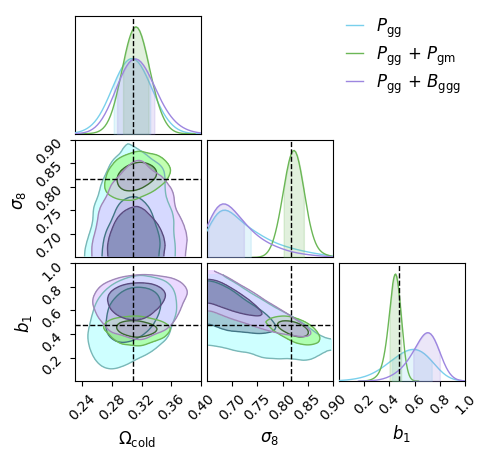

In [7]:
pf.plot_fig6_shame_contours()


## 7. Number density: SHAMe vs phase-matched mocks

Ensemble posteriors (P + P$_{\rm gm}$ + B) for the SHAMe high-fidelity mock at 3 number densities (filled), and the phase-matched mock (SHAMe ICs + our forward model, mean of 10 noise realizations) at the same densities (unfilled, orange shades matched by $\bar{n}$). Matched and SHAMe share the truth at each $\bar{n}$; the offset between a filled and unfilled contour of the same shade is the model-mismatch part of the SHAMe bias. (Replaces the noisy/noiseless CV-mean overlays.)

In [8]:
pf.plot_fig7_noise_impact_contours_nbars()


Missing fig 7 sample files:
  - noisy × $\bar{n}=1.1\times10^{-4}$: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_nbar0.00011_pred.npy
  - noisy × $\bar{n}=2.2\times10^{-4}$: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_nbar0.00022_pred.npy
  - noisy × $\bar{n}=5.4\times10^{-4}$: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_nbar0.00054_pred.npy
  - noisy

## 8. Scale dependence of constraints

**Fig. 8 (FoB):** SHAMe OOD FoB$(\Omega_m,\,\sigma_8,\,b_1)$ at fixed $k_\mathrm{max}^{P_{gg}}=0.37$, $K{=}3$ ensemble. Top: PGM $k_\mathrm{max}$ fixed at $0.24$, bispec on $x$; bottom: bispec fixed at $0.24$, PGM on $x$.


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.11 | tried: '_kp0.37_kb0.11': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.11_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.11_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.11_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.11_nbar0.00011_pred.npy


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.15 | tried: '_kp0.37_kb0.15': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.15_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.15_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.15_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.15_nbar0.00011_pred.npy


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.18 | tried: '_kp0.37_kb0.18': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.18_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.18_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.18_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.18_nbar0.00011_pred.npy


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.21 | tried: '_kp0.37_kb0.21': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.21_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.21_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.21_nbar0.00011_pred.npy


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.27 | tried: '_kp0.37_kb0.27': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.27_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.27_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.27_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.27_nbar0.00011_pred.npy


MISSING FoB3 point | panel=bispec sweep (PGM kmax=0.24 fixed) | stats=$P_\mathrm{gg}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00011 | k_max=0.31 | tried: '_kp0.37_kb0.31': member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.31_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_bispec_kp0.37_kb0.31_nbar0.00011_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_bispec_kp0.37_kb0.31_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_bispec_kp0.37_kb0.31_nbar0.00011_pred.npy


... (181 outputs left out)

MISSING FoB3 point | panel=joint sweep (k_B = k_Pgm) | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00054 | k_max=0.34 | tried: '_kp0.37_kpgm0.34_kb0.34': member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.34_kb0.34_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.34_kb0.34_nbar0.00054_pred.npy; member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.34_kb0.34_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.34_kb0.34_nbar0.00054_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.34_kb0.34_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_pgm_bispec_kp

MISSING FoB3 point | panel=joint sweep (k_B = k_Pgm) | stats=$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$ | nbar=_nbar0.00054 | k_max=0.37 | tried: '_kp0.37_kpgm0.37_kb0.37': member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.37_nbar0.00054_pred.npy; member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.37_nbar0.00054_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.37_kb0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_shame_pk_pgm_bispec_kp

Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/fig8_scale_dependence_fob3_nbars.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/fig8_scale_dependence_fob3_nbars.pdf


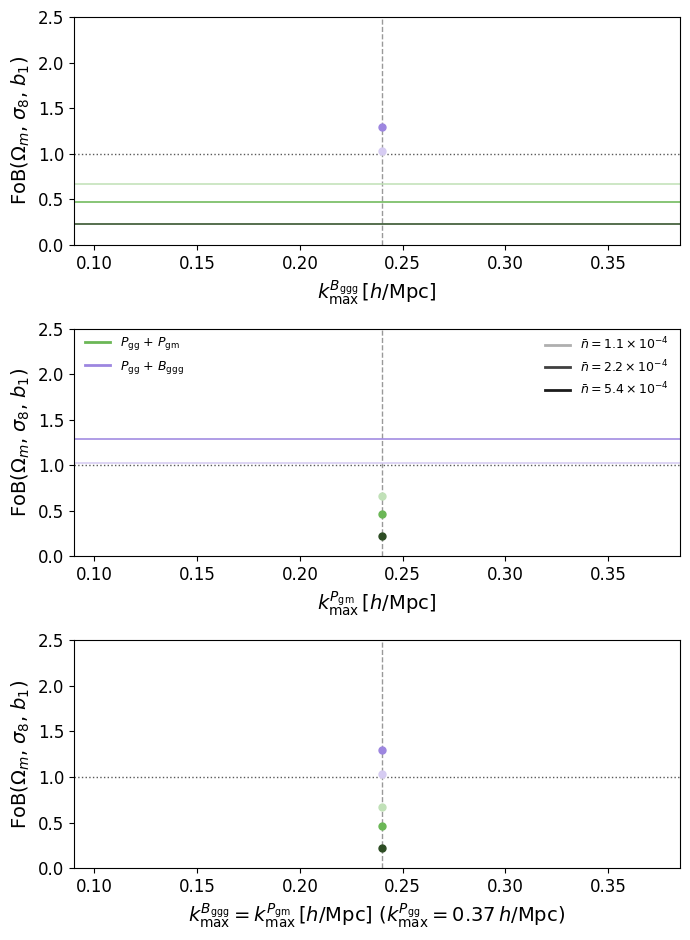

In [9]:
pf.plot_fig8_scale_dependence_fob3_nbars()


## 9. Overall $k_\mathrm{max}$ — FoM($\Omega_\mathrm{c}$, $\sigma_8$, $b_1$)

SHAMe OOD **marginal** FoM for each of the three key parameters vs a shared overall scale cut ($K{=}3$ ensemble), three panels. For $k_\mathrm{max}\le 0.24$ every statistic uses that cut; for $k_\mathrm{max}>0.24$, $P_{gg}$ continues while $B$ and $P_{gm}$ stay at $0.24$.


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/fig9_scale_dependence_fom_nbars.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/fig9_scale_dependence_fom_nbars.pdf


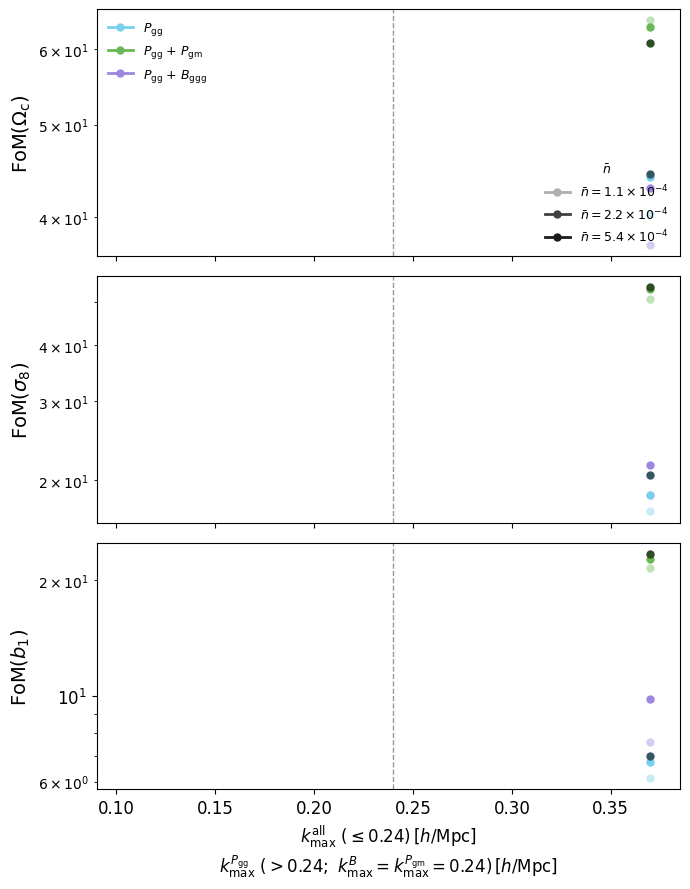

In [10]:
pf.plot_fig9_scale_dependence_overall_kmax_fom3_nbars()


## 10. Convergence: $P_{gg}+P_{gm}+B_{ggg}$ (3D FoM / FoB)

Coverage-test 3D FoM / FoB vs $N_\mathrm{train}$.


In [11]:
pf.plot_fig10_convergence_pgg_b_pgm()


=== Coverage grid: $P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ + $B(k_1,k_2,k_3)$ ===
tag_test = _muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly
grid: 6 bx × 7 n_cosmo = 42 points

MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ + $B(k_1,k_2,k_3)$] bx=1, n_cosmo=500: no model directory: sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain500_best-rand16
MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ + $B(k_1,k_2,k_3)$] bx=1, n_cosmo=1000: no model directory: sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain1000_best-rand16
MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ + $B(k_1,k_2,k_3)$] bx=1, n_cosmo=2000: no model directory: sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain2000_best-rand16
MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm

""


## 11. Convergence: all stat combos (marginal FoM / FoB)

Coverage-test marginal FoM / FoB vs $N_\mathrm{train}$ for each fiducial statistics combination.


=== Coverage grid: $P_\mathrm{gg}(k)$ ===
tag_test = _muchisimocks_pk_kp0.37_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly
grid: 6 bx × 7 n_cosmo = 42 points

MISSING  [$P_\mathrm{gg}(k)$] bx=1, n_cosmo=500: no model directory: sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain500_best-rand16
MISSING  [$P_\mathrm{gg}(k)$] bx=1, n_cosmo=1000: no model directory: sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain1000_best-rand16
MISSING  [$P_\mathrm{gg}(k)$] bx=1, n_cosmo=2000: no model directory: sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain2000_best-rand16
MISSING  [$P_\mathrm{gg}(k)$] bx=1, n_cosmo=4000: no model directory: sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain4000_best-rand16
MISSING  [$P_\mathrm{gg}(k)$] bx=1, n_cosmo=6000: no model directory: sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noise

INCOMPLETE [$P_\mathrm{gg}(k)$] bx=32, n_cosmo=10000: loaded (inprogress); shape=(10000, 1000, 11); usable=140/1000 target; stored=1000 (860 all-NaN/failed rows dropped); still inprogress — final _pred.npy not written yet

Summary [$P_\mathrm{gg}(k)$]: 1 loaded (0 complete, 1 incomplete) / 42 expected; 41 missing

Wrote cache: /scratch/kstoreyf/muchisimocks/results_v2/paper_figures_cache/df_conv_pk_kp0.37_b1phys_err_ensK3_top3_settings_ip.pkl
$P_\mathrm{gg}(k)$: 1 grid points loaded (1 incomplete)
=== Coverage grid: $P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ ===
tag_test = _muchisimocks_pk_pgm_kp0.37_kpgm0.24_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly
grid: 6 bx × 7 n_cosmo = 42 points

MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$] bx=1, n_cosmo=500: no model directory: sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain500_best-rand16
MISSING  [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$] bx=1, n_cosmo=1000: no model directo

INCOMPLETE [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$] bx=32, n_cosmo=10000: loaded (inprogress); shape=(10000, 1000, 11); usable=110/1000 target; stored=1000 (890 all-NaN/failed rows dropped); still inprogress — final _pred.npy not written yet

Summary [$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$]: 1 loaded (0 complete, 1 incomplete) / 42 expected; 41 missing

Wrote cache: /scratch/kstoreyf/muchisimocks/results_v2/paper_figures_cache/df_conv_pk_pgm_kp0.37_kpgm0.24_b1phys_err_ensK3_top3_settings_ip.pkl
$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$: 1 grid points loaded (1 incomplete)
=== Coverage grid: $P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$ ===
tag_test = _muchisimocks_pk_bispec_kp0.37_kb0.24_coveragev2_p5_n1000_biasnoisecoveragev2_p9_n1000_noisefly
grid: 6 bx × 7 n_cosmo = 42 points

MISSING  [$P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$] bx=1, n_cosmo=500: no model directory: sbi_muchisimocks_pk_bispec_kp0.37_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx1_ntrain500_best-rand16
MISSING  [$P_

INCOMPLETE [$P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$] bx=32, n_cosmo=10000: loaded (inprogress); shape=(10000, 1000, 11); usable=120/1000 target; stored=1000 (880 all-NaN/failed rows dropped); still inprogress — final _pred.npy not written yet

Summary [$P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$]: 1 loaded (0 complete, 1 incomplete) / 42 expected; 41 missing

Wrote cache: /scratch/kstoreyf/muchisimocks/results_v2/paper_figures_cache/df_conv_pk_bispec_kp0.37_kb0.24_b1phys_err_ensK3_top3_settings_ip.pkl
$P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$: 1 grid points loaded (1 incomplete)
Loaded cache: /scratch/kstoreyf/muchisimocks/results_v2/paper_figures_cache/df_conv_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_b1phys_err_ensK3_top3_settings_ip.pkl
No coverage grid for $P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$ + $B(k_1,k_2,k_3)$


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/fig11_convergence_all_combos.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/fig11_convergence_all_combos.pdf


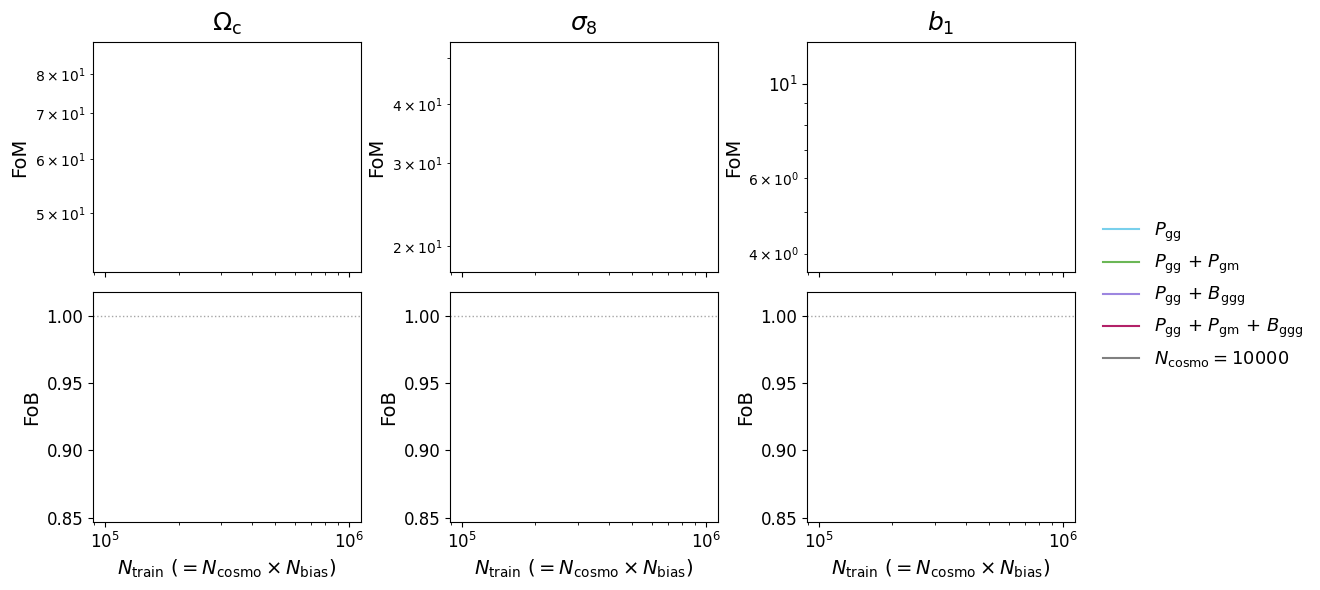

,bx,n_cosmo,n_sims,n_cov,n_stored,status,kind,fom_omega_m,fob_omega_m,fom_sigma8,...,fob_b1,mse_omega_m,delta_omega_m,mse_sigma8,delta_sigma8,mse_b1,delta_b1,fom_3d,fob3,stat_combo
0,32,10000,320000,140,1000,incomplete,inprogress,42.355881,0.968114,18.499488,...,0.921070,0.000443,0.001068,0.002494,0.004520,0.053222,-0.026689,5440.680968,1.811740,$P_\mathrm{gg}(k)$
1,32,10000,320000,110,1000,incomplete,inprogress,86.035347,0.877307,51.422439,...,0.898277,0.000092,-0.001049,0.000301,-0.000135,0.006015,0.003638,101947.738832,1.758910,$P_\mathrm{gg}(k)$ + $P_\mathrm{gm}(k)$
2,32,10000,320000,120,1000,incomplete,inprogress,51.606274,0.854385,21.593089,...,0.958031,0.000251,-0.000323,0.002062,-0.010866,0.020624,0.024245,15719.502473,1.785263,"$P_\mathrm{gg}(k)$ + $B(k_1,k_2,k_3)$"


In [12]:
pf.plot_fig11_convergence_all_combos()


---
## Appendix A. Mean-of-stats vs per-realization


In [13]:
pf.plot_figA_mean_vs_indiv_means_contours()


FileNotFoundError: ensemble CV-mean missing: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy; member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_muchisimocks_pk_pgm_bispec_kp0.37_kpgm

## Appendix B. Full posteriors (cosmic variance & SHAMe)


In [14]:
pf.plot_figB1_cosmic_variance_full_posteriors()


  ensemble missing [$P_\mathrm{gg}$]: member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_muchisimocks_pk_kp0.37_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy; member 2: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_kp0.37_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest2/samples_test_muchisimocks_pk_kp0.37_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pred.npy
  ensemble missing [$P_\mathrm{gg}$ + $P_\mathrm{gm}$]: member 1: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_kp0.37_kpgm0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16_nbest1/samples_test_muchisimocks_pk_pgm_kp0.37_kpgm0.24_cvshamev2_p0_n1000_biasshame0.00022_noisebest_p0_n1_noisefly_mean_pre

  ensemble missing [$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{ggg}$]: member 0: missing /scratch/kstoreyf/muchisimocks/results_v2/results_sbi/sbi_muchisimocks_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_p5_n10000_biasnoisenestv2_p9_n320000_noisefly_rp_bx32_ntrain10000_best-rand16/samples_test_shame_pk_pgm_bispec_kp0.37_kpgm0.24_kb0.24_nbar0.00022_pred.npy


Saved: /home/kstoreyf/muchisimocks/figures/2026-11-20_paper_figures/figB2_shame_full_posteriors.pdf


Saved: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest/figB2_shame_full_posteriors.pdf


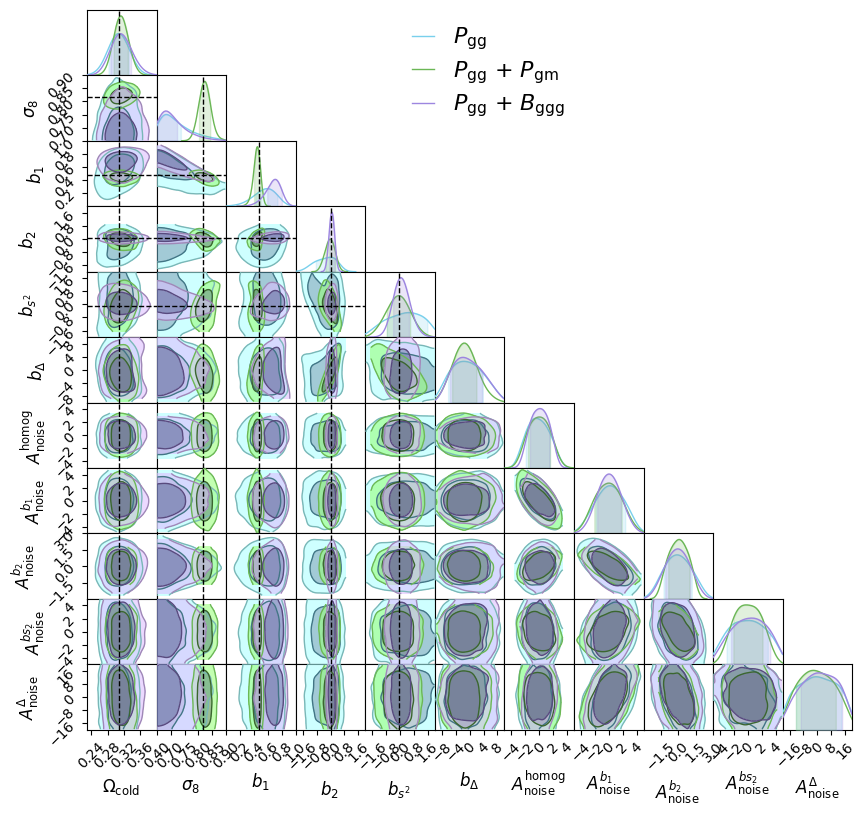

In [15]:
pf.plot_figB2_shame_full_posteriors()
